Simulating hodgkin huxley neurons in C++
This is just a quick bit of testing, but may provide a base for an improved version of the simulator

Basic features:
Single compartment conductance based neurons
Voltage and ligand gating 
Simple conductance based synapses

Conductance based neurons:
Resting membrane potential defined in terms of membrane conductances for each ion # Nernst potentials for Na, K, Cl, and Ca, and 
Monoexponential gating defined in terms of Vhalf, Vk, theta0 theta1 sig0 k0

The fundamental principle guiding the simulation code is that we avoid any conditional (if) statements. This means we end up doing a lot of unnecessary calculations, but it allows us to run the code on a GPU which more thank makes up for it. 
I dont like the idea of current injection, or even of bias currents. I think its unphysiological to have a constant current that does not changed based on neural or external conditions.  

Extra features:
Multicompartments
ChatGPT compile python to c++
Delays
Gap junctions 
Short term plasticity
Long term calcium based plasticity 

In [5]:
from auxillaryFunctions import *

def calcPerfStats(channelData):
    pStatArray = channelData["performanceStats"]
    perfStats = {
        "initialization Time": pStatArray[0],
        "channel Time": pStatArray[1],
        "accumulate Time": pStatArray[2],
        "diffusive Time": pStatArray[3],
        "neuron Time": pStatArray[4],
        "spiker Time": pStatArray[5],
        "recording Time": pStatArray[6],
        "total Time": pStatArray[7]
    }
    return perfStats

def trackPerfOverTime(channelData):
    from datetime import datetime
    timeStamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
    perfStats = calcPerfStats(channelData)
    perfStats["timeStamp"] = timeStamp
    #save as a pickled list of dictionaries using numpy.save
    if os.path.exists("performanceStats.npy"):
        currentStats = np.load("performanceStats.npy",allow_pickle=True).tolist()
    else:
        currentStats = []
    currentStats.append(perfStats)
    np.save("performanceStats.npy",currentStats,allow_pickle=True)

np.random.seed(0)
#neurons
#NOTE: This latest update began as me wanting to add the ability to simulate neurons and add spikers, but has changed into me trying to better initialize sims
STNchannels = np.load(r"tools\translatedSTNchannels2.npy",allow_pickle=True).item()
GPechannels = np.load(r"tools\translatedGPechannels2.npy",allow_pickle=True).item()
STNbias = -2.25
GPeBias = -.23 #-0.23

TS = 0.05  
simScale = 250
nSTN,nGPe,nIdk = simScale,3*simScale,0
nCTX,nMSN = 10*simScale, 30*simScale
CTXrate,MSNrate = 3.3,2.1 #3.3,2.1
k = 10
nSTN_GPe,nGPe_GPe,nGPe_STN,nCTX_STN,nMSN_GPe = k*nSTN,k*nGPe,k*nGPe,k*nSTN,k*nGPe


STNDendriteMap = []
STNDendriteInfo = []

STNNeurons = [Neuron(i,"STN","excitatory",AISchannels=STNchannels,AISbias=STNbias,denderiteInfo=STNDendriteInfo,dendriteMap=STNDendriteMap) for i in range(nSTN)]
GPeNeurons = [Neuron(i,"GPe","inhibitory",AISchannels=GPechannels,AISbias=GPeBias) for i in range(nGPe)]
idkNeurons = [Neuron(i,"idk","inhibitory",AISchannels=GPechannels,AISbias=GPeBias) for i in range(nIdk)]

CTXSpikers = [Spiker(i,"CTX","excitatory",CTXrate,TS) for i in range(nCTX)]
MSNSpikers = [Spiker(i,"MSN","inhibitory",MSNrate,TS) for i in range(nMSN)]

neuronDict = {"STN":STNNeurons,"GPe":GPeNeurons}
spikerDict = {"CTX":CTXSpikers,"MSN":MSNSpikers}

CTXToSTNSynapses = createSynapses(CTXSpikers,STNNeurons,nCTX_STN,0.015,0.2,TS)
STNToGPeSynapses = createSynapses(STNNeurons,GPeNeurons,nSTN_GPe,0.015,4,TS) #
GPeToSTNSynapses = createSynapses(GPeNeurons,STNNeurons,nGPe_STN,0.5,4,TS)
GPeToGPeSynapses = createSynapses(GPeNeurons,GPeNeurons,nGPe_GPe,0.025,4,TS)
MSNToGPeSynapses = createSynapses(MSNSpikers,GPeNeurons,nGPe_GPe,0.02,0.2,TS)

synapseDict = {"CTXToSTN":CTXToSTNSynapses,"STNToGPe":STNToGPeSynapses,"GPeToSTN":GPeToSTNSynapses,
                "GPeToGPe":GPeToGPeSynapses,"MSNToGPe":MSNToGPeSynapses}


simData,connectionToChannelMap = genSimData(neuronDict,spikerDict,synapseDict,TS)
print(f"Total number of channels {simData['nChannels']}")

Total number of channels 76000


In [6]:
build_dir,configType = "build", "Release" #"Debug" Release ##NOTE: make sure your are using correct version
moduleDir = os.path.join(build_dir, configType)
if moduleDir not in sys.path:
    sys.path.append(moduleDir)

import cathalTest

def solveSystemCpp(ac,TS,runTime,samplingInterval=2,stimInfoSpikes={},stimInfoCurrents = {}, recordingKeys = ["voltages","calciumVals","netCurrent","current"]):
    nIterations = int(runTime/TS)
    nSamples = int(np.ceil(nIterations/samplingInterval))
    spikeStimTimes,spikeStimNeurons = genSpikeStimArrays(stimInfoSpikes)
    ac["spikeStimTimes"] = spikeStimTimes
    ac["spikeStimNeurons"] = spikeStimNeurons

    biasStimTimes,biasStimSegments,biasStimValues = genBiasStimArrays(stimInfoCurrents)
    ac["biasStimTimes"] = biasStimTimes
    ac["biasStimSegments"] = biasStimSegments
    ac["biasStimValues"] = biasStimValues
    ac["performanceStats"] = np.zeros(8,dtype=np.float32)


    recordingData = {}
    for key in recordingKeys:
        shape = [nSamples] + list(ac[key].shape)
        recordingData[key] = np.zeros(shape,dtype=np.float32) #np.ascontiguousarray

    tv = np.linspace(0,runTime,nSamples)
    print("here")
    cathalTest.solveNeuralSystem(ac,recordingData,TS,nIterations,samplingInterval)

    trackPerfOverTime(ac)

    recordingData["time"] = tv
    return recordingData

simDataPy = deepcopy(simData)
stimInfoSpikes,stimInfoCurrents = {},{}
runTime = 1000
allChannelDataCpp = deepcopy(simData)
allChannelDataCpp["debugRecording"] = np.zeros_like(simDataPy["current"])
dataCpp = solveSystemCpp(allChannelDataCpp,TS,runTime,samplingInterval=4,stimInfoSpikes=stimInfoSpikes,
                         recordingKeys = ["voltages","calciumVals","current"])
#"calciumVals","netCurrent","current","spikeBuffer","debugRecording"

#basically, recording the spikeBuffer is a nightmare, performance wise
#analysis shows, as was my intention, that the bottleneck is solving the channels (75%)
#The next slowest part is solving the spikers (10%)  (cause theres so many), 
# following by recording (6%)
#takes about 2.2 seconds
#NOTE: August 14: I have gotten openMP working so we can start looking at that for optimization
#NOTE: Aug 15: The 5 optimizations I want to try: openMP, making spike buffer len a power of 2 (no difference), 
#               precalculating indices, creating a struct, parallelizing spiker solve
#NOTE: Using openMP is slower, need to figure out why. FIXED: used more threads, smaller chunks
#NOTE: Did some optimizations to the spike solver, parallelized and imrpoved RNG, 
#       took a full second off the run time(60% faster overall)
#02 opt with 1k neurons is 4.6 x real time. Accumulate is starting to cause issues. 




here
Elapsed time in seconds: 7.734904800000001


(-0.1, 100.1)

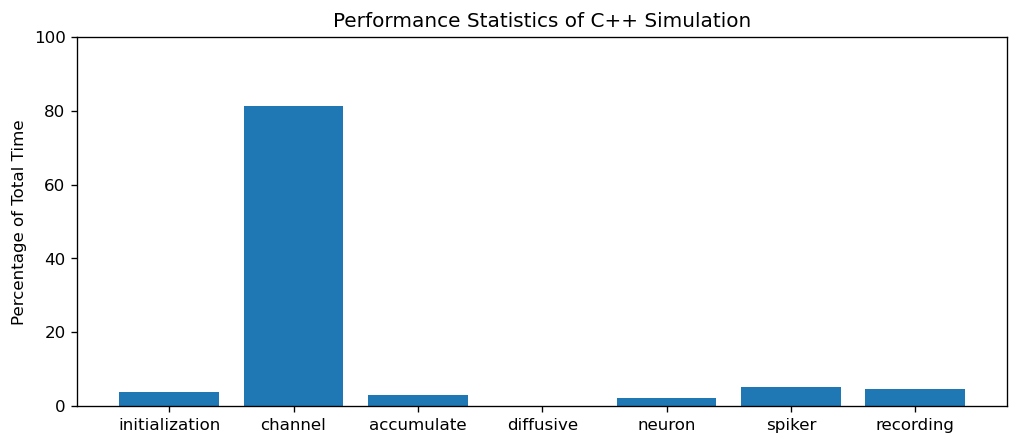

In [7]:
perfStats = calcPerfStats(allChannelDataCpp)

fig,ax = plt.subplots(1,1,figsize=(10,4),dpi=120)
keys,vals = [],[]
for key,val in perfStats.items():
    if key not in ["timeStamp","total Time"]:
        keys.append(key.split(" ")[0])  #remove the " Time" part
        vals.append(100*val/perfStats["total Time"])  #convert to percentage
ax.bar(keys,vals)
ax.set_ylabel("Percentage of Total Time")
ax.set_title("Performance Statistics of C++ Simulation")
ax.set_ylim(-0.1,100.1)

#standardPlot(dataCpp)

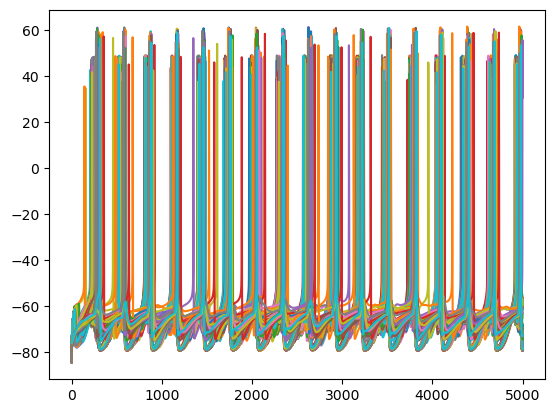

In [4]:
plt.plot(dataCpp["voltages"][:,0:300]);

122
122


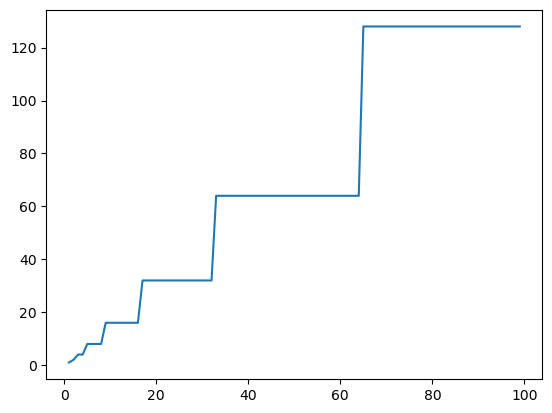

In [7]:
# stimInfoSpikes = {}
# # stimSynapse(stimInfoSpikes,[17,19],10,11,TS)
# # stimSynapse(stimInfoSpikes,[17,20],9,11,TS)

# runTime = 1
# stimInfoCurrents = {} 
# stimBiasCurrent(stimInfoCurrents,segmentsToStim=[0,2],currentValue=2.0,startTime=12,stopTime=20,TS=TS)

# simDataPy = deepcopy(simData)
# simDataPy["debugRecording"] = np.zeros_like(simDataPy["current"])
# data = solveSystemStandard(simDataPy,TS,runTime,stimInfoSpikes,stimInfoCurrents,
#                            recordingKeys = ["voltages","calciumVals","netCurrent","current","spikeBuffer","debugRecording"])
# standardPlot(data)
# #plt.plot(data["time"],data["debugRecording"][:,synapsesToStim])




# const int mask = maxDelayInt-1;
# int readIndex = (writeIndex[pre] - inputDelay[idx]) & mask;
mask = simData["maxDelayInt"] - 1
simData["writeIndex"] # some int
writeIndex =  5
inputDelay = 11
readIndex = (writeIndex - inputDelay) & mask
print(readIndex)
readIndex = int((writeIndex-inputDelay)%simData["maxDelayInt"])
print(readIndex)

#1 2, 2 4, 3, 4, 
nextPower2 = lambda x: 2**(np.ceil(np.log2(x)))
x = np.arange(1,100)
y = nextPower2(x)
plt.plot(x,y)
